Day 3 - Personal extra on larger dataset

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.model_selection import RepeatedStratifiedKFold, RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import roc_auc_score, f1_score, RocCurveDisplay

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("magic04.data", header=None)

X = df.drop(columns=[10])
y = df[10].map({"g": 1, "h": 0})

print(X.shape)
print(y.value_counts())


(19020, 10)
10
1    12332
0     6688
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 42, stratify=y
)

In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Boosting": GradientBoostingClassifier(random_state=42)
}

In [12]:
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    print(f"{name}: {accuracy:.3f}")

Decision Tree: 0.821
Random Forest: 0.883
Boosting: 0.877


In [13]:
rfc = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 4, 6, 8, 10, 12],
    "min_samples_split": randint(2, 15),
    "min_samples_leaf": randint(1, 8),
    "max_features": ["sqrt", "log2"]
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rfc,
    n_iter=20,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)
search.fit(X_train, y_train)

best_rf = search.best_estimator_

train_auc = search.cv_results_["mean_train_score"][search.best_index_]
cv_auc = search.best_score_
test_auc = roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])

print("Best settings:", search.best_params_)
print("Train AUC:", round(train_auc, 4))
print("CV AUC:   ", round(cv_auc, 4)) 
print("Test AUC: ", round(test_auc, 4))

Best settings: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 9, 'n_estimators': 487}
Train AUC: 0.9971
CV AUC:    0.9321
Test AUC:  0.9367


Decision Tree: Accuracy 0.821 | F1 0.861 | ROC-AUC 0.806
Random Forest: Accuracy 0.883 | F1 0.913 | ROC-AUC 0.935
Boosting: Accuracy 0.877 | F1 0.909 | ROC-AUC 0.924
Tuned Random Forest: Accuracy 0.882 | F1 0.912 | ROC-AUC 0.937


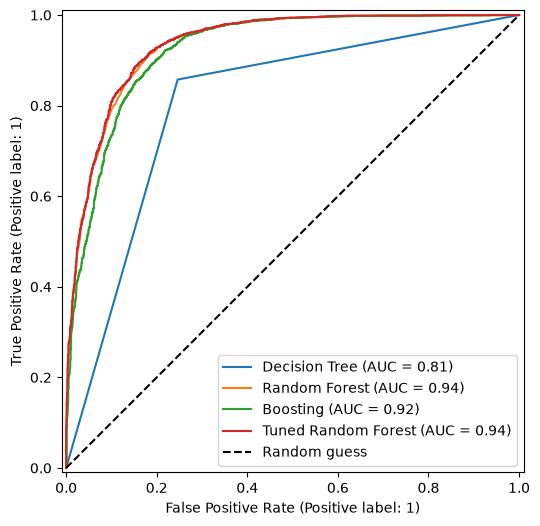

In [14]:
models["Tuned Random Forest"] = best_rf

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    print(f"{name}: Accuracy {accuracy_score(y_test, predictions):.3f} | "
          f"F1 {f1_score(y_test, predictions):.3f} | ROC-AUC {roc_auc_score(y_test, probs):.3f}")
    RocCurveDisplay.from_predictions(y_test, probs, name=name, ax=ax)

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.show()

Funny enough, Random forest again performed on par with tuned version. 